In [ ]:
# Kéo repo của nhóm về Colab
!git clone https://github.com/khoagrai/BTL_ML.git
%cd BTL_ML

# Import hàm tiền xử lý
from preprocess import load_and_preprocess_data

# Load dữ liệu đã xử lý
X_train, X_test, y_train, y_test = load_and_preprocess_data(
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Kích thước tập Train:", X_train.shape)
print("Kích thước tập Test :", X_test.shape)

Cloning into 'BTL_ML'...
remote: Enumerating objects: 10, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 10 (delta 1), reused 7 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (10/10), 164.36 KiB | 6.09 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/content/BTL_ML/BTL_ML/BTL_ML
Kích thước tập Train: (5625, 30)
Kích thước tập Test : (1407, 30)


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Khởi tạo và huấn luyện mô hình Gradient Boosting mặc định
gb_base = GradientBoostingClassifier(random_state=42)
gb_base.fit(X_train, y_train)

print("Đã huấn luyện xong mô hình Gradient Boosting mặc định!")

Đã huấn luyện xong mô hình Gradient Boosting mặc định!


In [ ]:
from sklearn.model_selection import GridSearchCV

# Lưới tham số nhỏ gọn (2 x 2 x 2 = 8 tổ hợp)
param_grid = {
    'n_estimators': [100, 150],  # Số lượng cây
    'learning_rate': [0.05, 0.1],  # Tốc độ học
    'max_depth': [3, 4],  # Độ sâu tối đa của mỗi cây
}

# Tìm bộ tham số tốt nhất bằng 3-Fold Cross Validation
grid_gb = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
)
grid_gb.fit(X_train, y_train)

# Lưu lại mô hình tốt nhất
best_gb = grid_gb.best_estimator_
print('Bộ tham số tốt nhất tìm được:', grid_gb.best_params_)

Bộ tham số tốt nhất tìm được: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 150}


In [ ]:
import pandas as pd

# Lấy độ quan trọng của 30 đặc trưng và chọn ra Top 10
importances = pd.Series(
    best_gb.feature_importances_, index=X_train.columns
).sort_values(ascending=False)
top10_cols = importances.head(10).index.tolist()

print("10 đặc trưng quan trọng nhất:", top10_cols)

# Huấn luyện thử mô hình chỉ dùng đúng 10 đặc trưng này
gb_top10 = GradientBoostingClassifier(**grid_gb.best_params_, random_state=42)
gb_top10.fit(X_train[top10_cols], y_train)

10 đặc trưng quan trọng nhất: ['tenure', 'InternetService_Fiber optic', 'TotalCharges', 'PaymentMethod_Electronic check', 'MonthlyCharges', 'Contract_Two year', 'Contract_One year', 'OnlineSecurity_Yes', 'PaperlessBilling_Yes', 'TechSupport_Yes']


GradientBoostingClassifier(learning_rate=0.05, max_depth=4, n_estimators=150,
                           random_state=42)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


# Hàm tính nhanh 5 chỉ số đánh giá
def evaluate(model, X_data, y_data, name):
  y_pred = model.predict(X_data)
  y_prob = model.predict_proba(X_data)[:, 1]
  return {
      'Phiên bản mô hình': name,
      'Accuracy': round(accuracy_score(y_data, y_pred), 4),
      'Precision': round(precision_score(y_data, y_pred), 4),
      'Recall': round(recall_score(y_data, y_pred), 4),
      'F1-Score': round(f1_score(y_data, y_pred), 4),
      'ROC-AUC': round(roc_auc_score(y_data, y_prob), 4),
  }


# Tạo bảng so sánh
df_results = pd.DataFrame([
    evaluate(gb_base, X_test, y_test, '1. GB Mặc định (30 đặc trưng)'),
    evaluate(best_gb, X_test, y_test, '2. GB Đã tinh chỉnh (30 đặc trưng)'),
    evaluate(
        gb_top10,
        X_test[top10_cols],
        y_test,
        '3. GB Đã tinh chỉnh (Top 10 đặc trưng)',
    ),
])

display(df_results)

,Phiên bản mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,1. GB Mặc định (30 đặc trưng),0.7953,0.6378,0.5321,0.5802,0.8407
1,2. GB Đã tinh chỉnh (30 đặc trưng),0.7960,0.6338,0.5508,0.5894,0.8420
2,3. GB Đã tinh chỉnh (Top 10 đặc trưng),0.7910,0.6250,0.5348,0.5764,0.8381


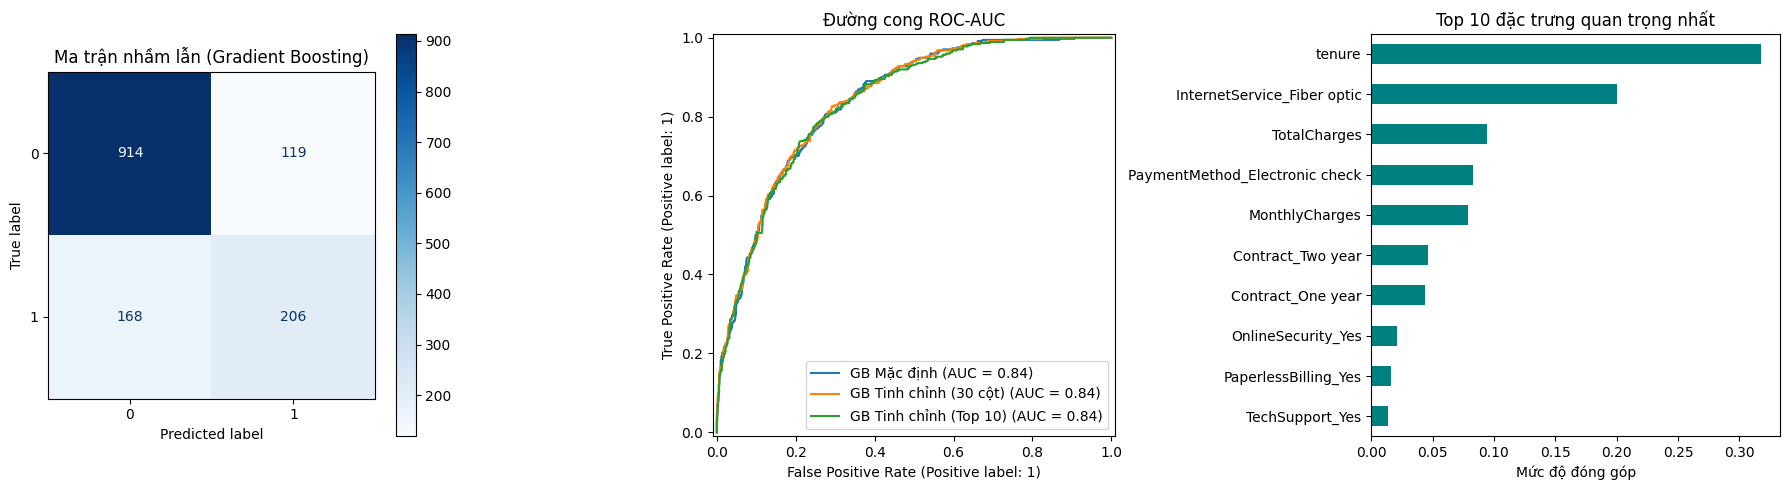

Đã lưu file mô hình: gradient_boosting_model.pkl


In [ ]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Vẽ Confusion Matrix của mô hình tốt nhất
ConfusionMatrixDisplay.from_estimator(
    best_gb, X_test, y_test, ax=axes[0], cmap='Blues'
)
axes[0].set_title('Ma trận nhầm lẫn (Gradient Boosting)')

# 2. Vẽ đường cong ROC so sánh 3 phiên bản
RocCurveDisplay.from_estimator(
    gb_base, X_test, y_test, ax=axes[1], name='GB Mặc định'
)
RocCurveDisplay.from_estimator(
    best_gb, X_test, y_test, ax=axes[1], name='GB Tinh chỉnh (30 cột)'
)
RocCurveDisplay.from_estimator(
    gb_top10,
    X_test[top10_cols],
    y_test,
    ax=axes[1],
    name='GB Tinh chỉnh (Top 10)',
)
axes[1].set_title('Đường cong ROC-AUC')

# 3. Vẽ biểu đồ Top 10 đặc trưng quan trọng nhất
importances.head(10).sort_values().plot(
    kind='barh', ax=axes[2], color='teal'
)
axes[2].set_title('Top 10 đặc trưng quan trọng nhất')
axes[2].set_xlabel('Mức độ đóng góp')

plt.tight_layout()
plt.show()

# Lưu file mô hình lại để nộp kèm trong file zip của nhóm
joblib.dump(best_gb, 'gradient_boosting_model.pkl')
print('Đã lưu file mô hình: gradient_boosting_model.pkl')